### Decision Tree
* Decision tree: struktur yang merepresntasikan angka dari kemungkinan jalur keputusan dan hasil untuk masing-masing jalur menghasilkan kategori output.
* Regression tree: menghasilkan numberical outputs

### Entropi
Kita menggunakan **entropi** untuk mereprentasikan seberapa banyak informasi yang dapat dihasilkan oleh suatu pertanyaan.

Biasanya digunakan untuk merepresentasikan tingkat ketidakteraturan, tetapi disini digunakan untuk merepresentasikan ketidakpastian data.

Misalkan ada sekumpulan data S, yang masing-masing memiliki label klasifikasi C₁,...,Cn. * Semua titik data termasuk dalam satu kategori → tidak ada ketidakpastian nyata → keacakan rendah
* Semua titik data terdistribusi secara merata di seluruh kategori → memiliki ketidakpastian yang cukup besar → keacakan tinggi

## Istilah matematika
Jika ρi adalah rasio data yang diberi label sebagai kategori ci, keacakan dapat didefinisikan sebagai:

$H(S) = -ρ₁㏒₂ρ₁-...-ρn㏒ρn$

dimana:
* $pi$ adalah probabilitas dari kelas ke-i
* Jumlah $pi$ adalah 1 (total probabilitas)
* Logaritma berbasis 2 (karena pengukuran dalam bit)
* Jika $pi$ = 0, abaikan karena $ 0*log(0) = 0$

### Gambar 17-2 Grafik $-0*log(0)$

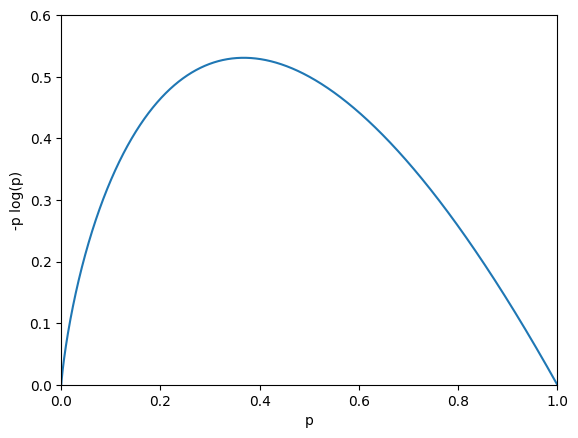

In [1]:
import matplotlib.pyplot as plt
import math

xs = [num / 10000 for num in range(10000)]
ys = [0] + [-num * math.log(num, 2) for num in xs if num > 0]

plt.plot(xs, ys)
plt.xlabel("p")
plt.ylabel("-p log(p)")
plt.axis([0, 1, 0, 0.6])

plt.show()

* Entropi akan menjadi kecil ketika $pi$ mendekati 0 atau 1
* Entropi akan menjadi besar ketika banya $pi$ tidak mendekati 0 (dengan arti data tersebar melintasi beberapa kelas)

In [2]:
# Fungsi entropy sebagai berikut

from typing import List

import math

def entropy(class_probabilities: List[float]) -> float:
    """Given a list of class probabilities, compute the entropy"""

    return sum(-p * math.log(p, 2) for p in class_probabilities
               if p > 0)                # ignore zero probabilites

### Tambahan

* `class_probabilities`: daftar angka yang mewakili probabilites masing-masing kelas.
* `for p in class_probabilities`: iterasi setiap probabilitas.
* `if > 0`: menghindari $log(0)$, karena itu tidak terdefinisi.
* `-p * math.log(p, 2)`: bagian dari rumus entropy. 
* `sum(..)`: menjumlahkan hasil untuk semua kelas

In [3]:
assert entropy([1, 0]) == 0
assert entropy([0.5, 0.5]) == 1
assert entropy([0.25, 0.75]) < 0.82

### Hasilnya

$ -0.5 log2 (0.5) -0.5 log2 (0.5) = -0.5 * (-1) - 0.5 * (-1) = 1.0 $
#
Artinya entropy = 1.0, yaitu maksimum untuk 2 kelas (sistem paling tidak pasti).

Data kita terdiri dari pasangan dalam bentuk (input, label) -> Kita perlu menghitung probabilitas klasifikasinya

In [4]:
from typing import Any
from collections import Counter

def class_probabilities(labels: List[Any]) -> List[float]:
    total_count = len(labels)
    return [count / total_count for count in Counter(labels).values()]

def data_entropy(labels: List[Any]) -> float:
    return entropy(class_probabilities(labels))

### Tambahan 
#### Tujuan dari `class_probabilites()` menghitung probabilitas label dalam data

labels = ['a', 'b', 'b', 'c']
* Counter(labels) → {'b': 2, 'a': 1, 'c': 1}
* total_count = 4
* Probabilitas: $[1/4, 2/4, 1/4] → [0.25, 0.5, 0.25]$

#### Tujuan dari `data_entropy` menghitung probabilitas dan entropy data

data_entropy(['yes', 'no', 'no']) 
* class_probabilities(['yes', 'no', 'no']) → [1/3, 2/3]
* entropy([1/3, 2/3]) = $-1/3*log2(1/3) - 2/3*log2(2/3) = 1/3 * (-1.584) + 2/3 * (-0.584) = 0.918$

In [5]:
assert data_entropy(['a']) == 0
assert data_entropy([True, False]) == 1
assert data_entropy([3, 4, 4, 4]) == entropy([0.25, 0.75])

### The Entropy of a Partition

* Subset yang diperoleh setelah segmentasi data memiliki gangguan yang lebih rendah → Gangguan segmentasi lebih rendah
* Subset yang diperoleh setelah segmentasi data memiliki gangguan yang lebih tinggi → Gangguan segmentasi lebih tinggi

Secara matematis, jika kita membagi data S menjadi beberapa subset S₁,...,Sm, yang berisi data dalam proporsi ｑ₁,...,ｑm.
Kita dapat menghitung gangguan segmentasi dengan penjumlahan tertimbang.

$H = ｑ₁H(S₁)+...+ｑmH(Sm)$

In [6]:
def partition_entropy(subsets: List[List[Any]]) -> float:
    """Returns the entropy  from this partition of data into subsets"""

    total_count = sum(len(subset) for subset in subsets)

    return sum(data_entropy(subset) * len(subset) / total_count for subset in subsets)

### Catatan

Pendekatan ini dengan banyak perbedaan nilai dapat menghasilkan entropy yang rendah karena overfitting, ketika menggunakan decision tree hindari bucket attribut large number value

### Creating a Decision Tree

* Node Keputusan: Setiap node keputusan mengajukan pertanyaan dan menunjuk ke arah yang berbeda sesuai dengan jawabannya
* Node Daun: Setiap node daun mewakili hasil prediksi

In [7]:
from typing import NamedTuple, Optional

class Candidate(NamedTuple):
    level: str
    lang: str
    tweets: bool
    phd: str
    did_well: Optional[bool] = None     # allow unlabeled data

In [8]:
inputs = [Candidate('Senior','Java',False,False,False),
    Candidate('Senior','Java',False,True,False),
    Candidate('Mid','Python',False,False,True),
    Candidate('Junior','Python',False,False,True),
    Candidate('Junior','R',True,False,True),
    Candidate('Junior','R',True,True,False),
    Candidate('Mid', 'R',True,True,True),
    Candidate('Senior','Python',False,False,False),
    Candidate('Senior','R',True,False,True),
    Candidate('Junior','Python',True,False,True),
    Candidate('Senior','Python',True,True,True),
    Candidate('Mid', 'Python',False,True,True),
    Candidate('Mid', 'Java',True,False,True),
    Candidate('Junior','Python',False,True,False)]      # level lang tweets phd did_well

### Menggunakan **algoritma ID3**
* If data memiliki label yang sama, menbuat simmpul daun dan nilai yang diprediksi adalah nilai label kemudian berhenti
* Jida daftar dari attribut adalah kosong (tidak ada pertanyaan yang ditanyakan) membuat a leaf node untuk prediksi label yang paling sering dan kemudian berhenti
* Jika tidak, coba membagi data setiap atribut
* Pilih membagi dengan entropy pembagi terendah
* Tambahkan decision node berdasarkan atribut yang dipilih
* ulangi setiap subset partisi menggunakan atribut yang tersisa

### Ini disebut algoritma Greedy 
karena setiap langkah memilih paling langsung opsi terbaik, mungkin tree lebih baik dengan gerekan ang terlihat buruk

In [9]:
# Make function to find the partition with the least entropy

from typing import Dict, TypeVar
from collections import defaultdict

T = TypeVar('T')        # generic type for input

# contoh partition_by(inputs, 'lang')
# → {'Java': [...], 'Python': [...], 'R': [...]}
def partition_by(inputs: List[T], attribute: str) -> Dict[Any, List[T]]:
    """Partition the inputs into lists based on the specified attribute"""

    partitions: Dict[Any, List[T]] = defaultdict(list)

    for input in inputs:
        key = getattr(input, attribute)     # value of the specified attribute
        partitions[key].append(input)        # add input to the correct partitions

    return partitions

# Untuk menghitung entropy

def partition_entropy_by(inputs: List[Any], attribute: str, label_attribute: str) -> float:
    """Compute the entropy corresponding to the partition"""

    # partitions consist of out inputs
    partitions = partition_by(inputs, attribute)

    # but partition_entropy need just the class labels
    labels = [[getattr(input, label_attribute) for input in partition]
               for partition in partitions.values()]

    return partition_entropy(labels)

In [10]:
# Kita ingin minimum-entropy partitions untuk seluruh kumpulan data

for key in ['level', 'lang', 'tweets', 'phd']:
    print(key, partition_entropy_by(inputs, key, 'did_well'))

level 0.6935361388961919
lang 0.8601317128547441
tweets 0.7884504573082896
phd 0.8921589282623617


Entropy lebih rendah berasal dari pemisahan pada level,
1. Kekacauan terendah diperoleh dengan segmentasi berdasarkan level

2. Untuk pencari kerja tingkat menengah, semua label yang sesuai adalah Benar

3. Untuk pencari kerja senior, label yang sesuai adalah Benar dan Salah
→**Kita perlu melakukan segmentasi lagi**

In [11]:
senior_inputs = [input for input in inputs if input.level == 'Senior']

for key in ['lang', 'tweets', 'phd']:
    print(key, partition_entropy_by(senior_inputs, key, 'did_well'))

lang 0.4
tweets 0.0
phd 0.9509775004326938


Untuk pencari kerja **senior**:

* Pencari kerja dengan atribut tweet ya: Sesuai dengan label Benar

* Pencari kerja dengan atribut tweet tidak: Sesuai dengan label Salah

In [12]:
junior_inputs = [input for input in inputs if input.level == 'Junior']

for key in ['lang', 'tweets', 'phd']:
    print(key, partition_entropy_by(junior_inputs, key, 'did_well'))

lang 0.9509775004326938
tweets 0.9509775004326938
phd 0.0



Untuk pencari kerja **junior**, pilih untuk melakukan segmentasi berdasarkan kolom phd

### Putting It All Together
### Tentukan pohon keputusan

* Daun: prediksi satu nilai
* Split: Berisi atribut yang akan dipisah, sub-pohon yang sesuai dengan atribut tertentu, dan nilai prediksi yang dapat digunakan saat menemukan nilai yang tidak diketahui


In [51]:
from typing import NamedTuple, Union, Any

class Leaf(NamedTuple):
    value: Any

class Split(NamedTuple):
    attribute: str
    subtrees: dict
    default_value: Any = None

DecisionTree = Union[Leaf, Split]

Gambarkan pohon keputusan rekrutmen sebagai objek Split:

In [52]:
hiring_tree=Split('level',{
    'Junior':Split('phd',{False:Leaf(True),True:Leaf(False)}),
    'Mid':Leaf(True),
    'Senior':Split('tweets',{False:Leaf(False),True:Leaf(True)})
})

In [58]:
# Jika Anda menemukan nilai atribut yang tidak diharapkan,
# Anda dapat menggunakan default_value untuk menangani situasi ini.

def classify(tree: DecisionTree, input: Any) -> Any:
    """Classify the input using the given decision tree"""

    # If this is a leaf node,  return its value
    if isinstance(tree, Leaf):
        return tree.value

    # Otherwise this tree consists of an attribute to split on
    # and a dictionary whose keys are values of that attribute
    # and whose values are subtrees to consider next
    subtree_key = getattr(input, tree.attribute)

    if subtree_key not in tree.subtrees:     # If no subtree for key,
        return tree.default_value           # return the default value.

    subtree = tree.subtrees[subtree_key]    # Choose the appropriate subtree
    return classify(subtree, input)          # and use it to classify the input.

Membangun representasi tree dari data training kita

In [59]:
def build_tree_id3(inputs: List[Any],
                   split_attributes: List[str],
                   target_attributes: str) -> DecisionTree:

    # Count target labels
    label_counts = Counter(getattr(input, target_attributes) for input in inputs)
    most_common_label = label_counts.most_common(1)[0][0]

    # If there's a unique label, predict it
    if len(label_counts) == 1:
        return Leaf(most_common_label)

    # If no split attributes left, return the majority label
    if not split_attributes:
        return Leaf(most_common_label)

    # Otherwise split by the best attribute
    def split_entropy(attribute: str) -> float:
        """Helper function for finding the best attribute"""

        return partition_entropy_by(inputs, attribute, target_attributes)

    best_attribute = min(split_attributes, key=split_entropy)

    partitions = partition_by(inputs, best_attribute)
    new_attributes = [a for a in split_attributes if a != best_attribute]

    # Recursively build the subtrees
    subtrees = {attribute_value: build_tree_id3(subset, new_attributes, target_attributes)
                for attribute_value, subset in partitions.items()}

    return Split(best_attribute, subtrees, default_value=most_common_label)

In [60]:
tree = build_tree_id3(inputs,['level','lang','tweets','phd'],'did_well')

In [61]:
classify(tree,Candidate("Junior","Java",True,False))

True

In [62]:
classify(tree,Candidate("Junior","Java",True,True))

False

In [63]:
classify(tree,Candidate("Intern","Java",True,True))

True